# 🏡 House Prices — Advanced Regression Techniques
### Compétition Kaggle | Prédiction du prix de vente de maisons à Ames, Iowa

---

**Objectif :** Prédire le prix de vente (`SalePrice`) de maisons résidentielles à partir de 79 variables descriptives.

**Métrique d'évaluation :** RMSLE (Root Mean Squared Logarithmic Error) — plus c'est bas, mieux c'est.

**Pipeline du projet :**
1. Chargement & exploration des données (EDA)
2. Nettoyage (valeurs manquantes, outliers, encodage)
3. Feature Engineering
4. Pipeline de prétraitement
5. Benchmark & optimisation des modèles
6. Stacking
7. Soumission Kaggle

---


## ⚙️ Étape 0 — Imports & Configuration

Chargement de toutes les librairies nécessaires : traitement des données, visualisation, modèles de machine learning.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats

from sklearn.model_selection import cross_val_score, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import GradientBoostingRegressor, StackingRegressor

try:
    from xgboost import XGBRegressor
    print("✓ XGBoost OK")
except:
    print("✗ XGBoost manquant")

try:
    from lightgbm import LGBMRegressor
    print("✓ LightGBM OK")
except:
    print("✗ LightGBM manquant")

try:
    from catboost import CatBoostRegressor
    print("✓ CatBoost OK")
except:
    print("✗ CatBoost manquant")

SEED = 42
sns.set_theme(style="whitegrid")
print("\nTout est prêt ✓")


✓ XGBoost OK
✓ LightGBM OK
✓ CatBoost OK

Tout est prêt ✓


## Étape 1 — Chargement des Données

Lecture des fichiers `train.csv` et `test.csv`. Séparation des identifiants et de la variable cible `SalePrice`.


In [2]:
TRAIN_PATH = "data/train.csv"
TEST_PATH  = "data/test.csv"

train = pd.read_csv(TRAIN_PATH)
test  = pd.read_csv(TEST_PATH)

print("Train :", train.shape)
print("Test  :", test.shape)
display(train.head(5))


Train : (1460, 81)
Test  : (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
train_ids = train["Id"].copy()
test_ids  = test["Id"].copy()

train = train.drop(columns=["Id"])
test  = test.drop(columns=["Id"])

TARGET = "SalePrice"

print(f"Prix min    : {train[TARGET].min():>10,.0f} $")
print(f"Prix max    : {train[TARGET].max():>10,.0f} $")
print(f"Prix médian : {train[TARGET].median():>10,.0f} $")
print(f"Prix moyen  : {train[TARGET].mean():>10,.0f} $")


Prix min    :     34,900 $
Prix max    :    755,000 $
Prix médian :    163,000 $
Prix moyen  :    180,921 $


## Étape 2 — Exploration de la variables cible et Vérification des valeurs manquantes

Analyse exploratoire **avant** toute modification : distribution de la cible, valeurs manquantes


### 2.1 — Distribution de SalePrice

Visualisation de la distribution brute et après transformation `log1p` — nécessaire pour normaliser la cible asymétrique.


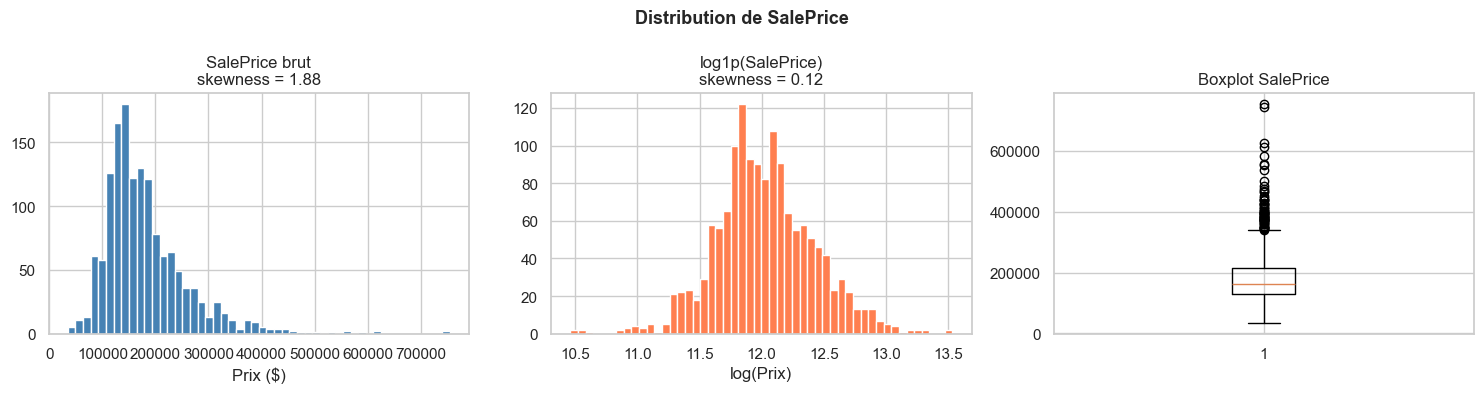

Skewness brut  : 1.883
Skewness log1p : 0.121


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(train[TARGET], bins=50, color="steelblue", edgecolor="white")
axes[0].set_title(f"SalePrice brut\nskewness = {train[TARGET].skew():.2f}")
axes[0].set_xlabel("Prix ($)")

log_price = np.log1p(train[TARGET])
axes[1].hist(log_price, bins=50, color="coral", edgecolor="white")
axes[1].set_title(f"log1p(SalePrice)\nskewness = {log_price.skew():.2f}")
axes[1].set_xlabel("log(Prix)")

axes[2].boxplot(train[TARGET])
axes[2].set_title("Boxplot SalePrice")

plt.suptitle("Distribution de SalePrice", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"Skewness brut  : {train[TARGET].skew():.3f}")
print(f"Skewness log1p : {log_price.skew():.3f}")


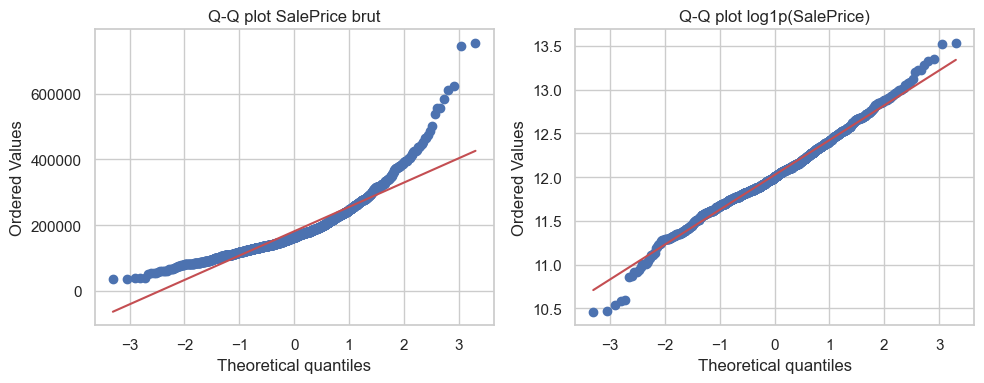

In [5]:
from scipy import stats
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

stats.probplot(train[TARGET], plot=axes[0])
axes[0].set_title("Q-Q plot SalePrice brut")

stats.probplot(np.log1p(train[TARGET]), plot=axes[1])
axes[1].set_title("Q-Q plot log1p(SalePrice)")

plt.tight_layout()
plt.show()

### 2.2 — Valeurs Manquantes

Inventaire des colonnes avec données manquantes dans le jeu d'entraînement, classées par pourcentage décroissant.


Colonnes du train avec des manquants : 19
Colonnes du test  avec des manquants : 33


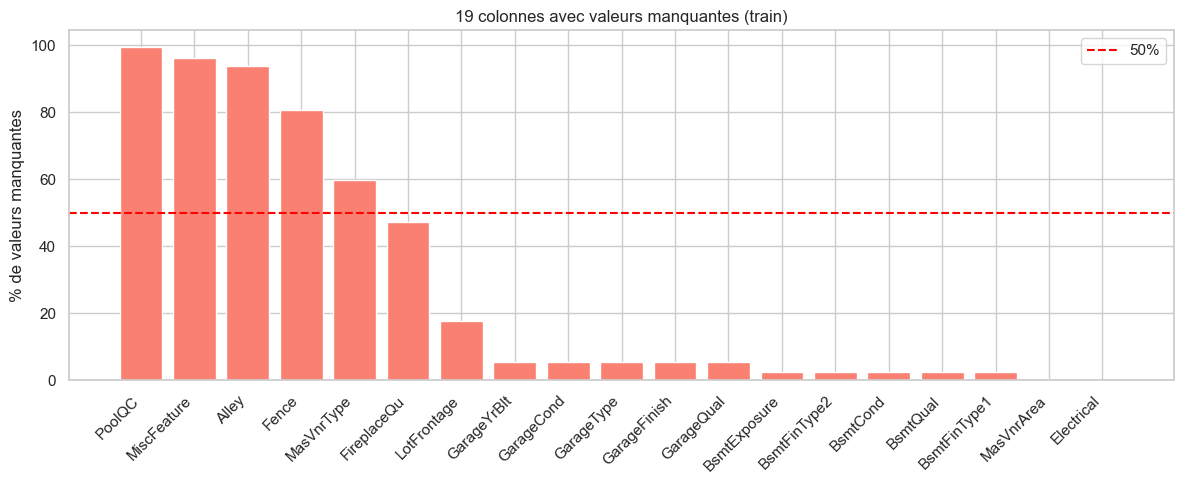

,manquants train,% train
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageYrBlt,81,5.5
GarageCond,81,5.5
GarageType,81,5.5


In [6]:
# --- Calcul train ---
missing_train = train.isnull().sum()
missing_pct_train = (missing_train / len(train) * 100).round(1)
missing_df_train = pd.DataFrame({
    "manquants train": missing_train,
    "% train": missing_pct_train
}).sort_values("% train", ascending=False)
missing_df_train = missing_df_train[missing_df_train["manquants train"] > 0]

# --- Calcul test ---
missing_test = test.isnull().sum()
missing_pct_test = (missing_test / len(test) * 100).round(1)
missing_df_test = pd.DataFrame({
    "manquants test": missing_test,
    "% test": missing_pct_test
}).sort_values("% test", ascending=False)
missing_df_test = missing_df_test[missing_df_test["manquants test"] > 0]

# --- Affichage ---
print(f"Colonnes du train avec des manquants : {len(missing_df_train)}")
print(f"Colonnes du test  avec des manquants : {len(missing_df_test)}")

# --- Graphique train ---
plt.figure(figsize=(12, 5))
plt.bar(missing_df_train.index, missing_df_train["% train"], color="salmon")
plt.xticks(rotation=45, ha="right")
plt.ylabel("% de valeurs manquantes")
plt.title(f"{len(missing_df_train)} colonnes avec valeurs manquantes (train)")
plt.axhline(50, color='red', linestyle='--', label='50%')
plt.legend()
plt.tight_layout()
plt.show()

# --- Deux tableaux côte à côte ---
from IPython.display import display, HTML

col1 = missing_df_train.to_html()
col2 = missing_df_test.to_html()

display(HTML(f"""
<div style="display: flex; gap: 40px;">
    <div>
        <h4>Train</h4>
        {col1}
    </div>
    <div>
        <h4>Test</h4>
        {col2}
    </div>
</div>
"""))

## Étape 3 — Nettoyage des Données

Traitement complet des valeurs manquantes (train & test), suppression des doublons, gestion des outliers et encodage ordinal des variables de qualité.


In [7]:
# Vérification : Doublons
nb_doublons = train.duplicated().sum()
if nb_doublons > 0:
    train = train.drop_duplicates().reset_index(drop=True)
    print(f"Doublons supprimés : {nb_doublons}")
else:
    print("Aucun doublon ✓")


Aucun doublon ✓


In [8]:
# Étape 1 : NaN train ET test (catégorielles = "None") 
none_cat = ["PoolQC","MiscFeature","Alley","Fence","MasVnrType",
            "FireplaceQu","GarageType","GarageFinish","GarageQual",
            "GarageCond","BsmtQual","BsmtCond","BsmtExposure",
            "BsmtFinType1","BsmtFinType2"]

for col in none_cat:
    train[col] = train[col].fillna("None")
    test[col]  = test[col].fillna("None")

# GarageYrBlt → médiane (0 = l'an 0 n'a pas de sens)
garage_median = train["GarageYrBlt"].median()
train["GarageYrBlt"] = train["GarageYrBlt"].fillna(garage_median)
test["GarageYrBlt"]  = test["GarageYrBlt"].fillna(garage_median)

# MasVnrArea → 0 si pas de maçonnerie, médiane sinon
masv_median = train["MasVnrArea"].median()
for df in [train, test]:
    mask = df["MasVnrType"] == "None"
    df.loc[mask, "MasVnrArea"] = df.loc[mask, "MasVnrArea"].fillna(0)
    df["MasVnrArea"] = df["MasVnrArea"].fillna(masv_median)

# LotFrontage → médiane du quartier
lot_median = train.groupby("Neighborhood")["LotFrontage"].median()
for df in [train, test]:
    mask = df["LotFrontage"].isna()
    df.loc[mask, "LotFrontage"] = df.loc[mask, "Neighborhood"].map(lot_median)
    df["LotFrontage"] = df["LotFrontage"].fillna(train["LotFrontage"].median())

print("NaN train + test traités ✓")
print(f"Manquants train : {train.isnull().sum().sum()}")
print(f"Manquants test  : {test.isnull().sum().sum()}")


NaN train + test traités ✓
Manquants train : 1
Manquants test  : 22


In [9]:
# Étape 2 : NaN train seulement 
elec_mode = train["Electrical"].mode()[0]
train["Electrical"] = train["Electrical"].fillna(elec_mode)
print(f"Electrical → mode = {elec_mode} ✓")


Electrical → mode = SBrkr ✓


In [11]:
# Étape 3 : NaN test seulement 
for col in ["BsmtFinSF1","BsmtFinSF2","BsmtUnfSF",
            "TotalBsmtSF","BsmtFullBath","BsmtHalfBath"]:
    mask = test["BsmtQual"] == "None"
    test.loc[mask, col] = test.loc[mask, col].fillna(0)
    test[col] = test[col].fillna(train[col].median())

for col in ["GarageCars","GarageArea"]:
    mask = test["GarageType"] == "None"
    test.loc[mask, col] = test.loc[mask, col].fillna(0)
    test[col] = test[col].fillna(train[col].median())

for col in ["MSZoning","KitchenQual","SaleType","Functional",
            "Exterior1st","Exterior2nd"]:
    test[col] = test[col].fillna(train[col].mode()[0])

# Utilities -> zéro variance → supprimer
train = train.drop(columns=["Utilities"], errors="ignore")
test  = test.drop(columns=["Utilities"],  errors="ignore")

print("NaN test seulement traités ✓")
print(f"Manquants train : {train.isnull().sum().sum()}")
print(f"Manquants test  : {test.isnull().sum().sum()}")


NaN test seulement traités ✓
Manquants train : 0
Manquants test  : 0


Variables avec outliers : 31 / 36


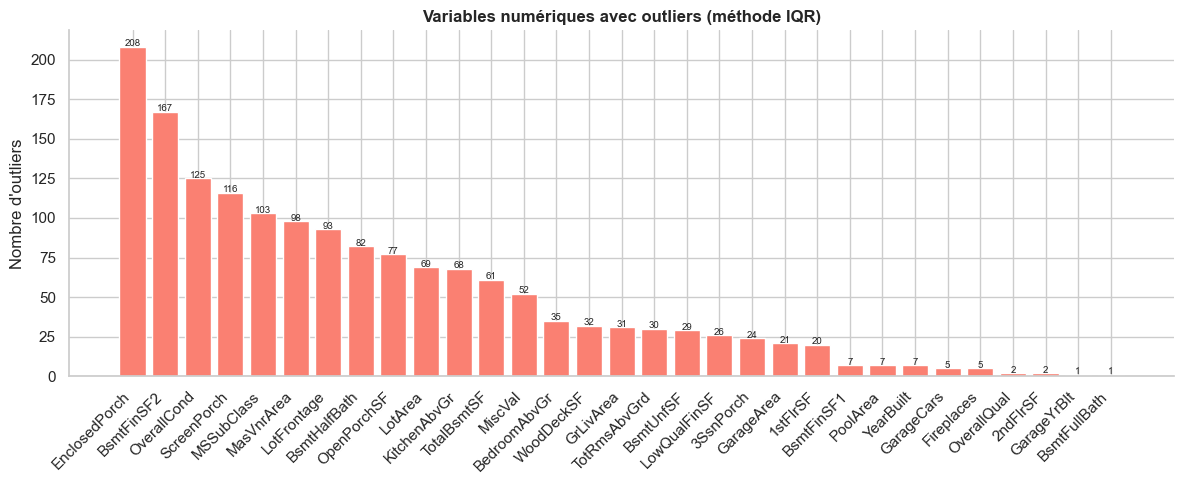

,nb_outliers
EnclosedPorch,208
BsmtFinSF2,167
OverallCond,125
ScreenPorch,116
MSSubClass,103
MasVnrArea,98
LotFrontage,93
BsmtHalfBath,82
OpenPorchSF,77
LotArea,69


In [12]:
# Étape 4 : Détection des outliers 

num_cols = [c for c in train.select_dtypes(include=np.number).columns 
            if c != TARGET]

# Compter les outliers par IQR
outlier_counts = {}
for col in num_cols:
    Q1  = train[col].quantile(0.25)
    Q3  = train[col].quantile(0.75)
    IQR = Q3 - Q1
    n_out = ((train[col] < Q1 - 1.5*IQR) | 
             (train[col] > Q3 + 1.5*IQR)).sum()
    if n_out > 0:
        outlier_counts[col] = n_out

outlier_df = pd.DataFrame.from_dict(
    outlier_counts, orient="index", columns=["nb_outliers"]
).sort_values("nb_outliers", ascending=False)

print(f"Variables avec outliers : {len(outlier_df)} / {len(num_cols)}")

# Graphique
fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(outlier_df.index, outlier_df["nb_outliers"],
              color="salmon", edgecolor="white")

# Valeur sur chaque barre
for bar, val in zip(bars, outlier_df["nb_outliers"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            str(val), ha="center", fontsize=7)

ax.set_ylabel("Nombre d'outliers")
ax.set_title("Variables numériques avec outliers (méthode IQR)",
             fontsize=12, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

display(outlier_df)

In [13]:
# Étape 5 : Gestion des Outliers (train seulement) 
# GrLivArea — 2 maisons documentées Kaggle
outlier_idx = train[(train["GrLivArea"] > 4000) &
                    (train[TARGET] < 300000)].index
train = train.drop(index=outlier_idx).reset_index(drop=True)
print(f"GrLivArea outliers supprimés : {len(outlier_idx)}")

# LotArea — skew extrême
Q1, Q3 = train["LotArea"].quantile(0.25), train["LotArea"].quantile(0.75)
lot_out = train[train["LotArea"] > Q3 + 3*(Q3-Q1)].index
train = train.drop(index=lot_out).reset_index(drop=True)
print(f"LotArea outliers supprimés   : {len(lot_out)}")

# TotalBsmtSF — 1 valeur ~6000
bsmt_out = train[train["TotalBsmtSF"] > 4000].index
train = train.drop(index=bsmt_out).reset_index(drop=True)
print(f"TotalBsmtSF outliers supprimés : {len(bsmt_out)}")

print(f"\nTrain après suppression : {train.shape}")


GrLivArea outliers supprimés : 2
LotArea outliers supprimés   : 32
TotalBsmtSF outliers supprimés : 0

Train après suppression : (1426, 79)


## 📊 Étape 4 — Exploration des Données (EDA)

## Visualisations des variables catégorielles

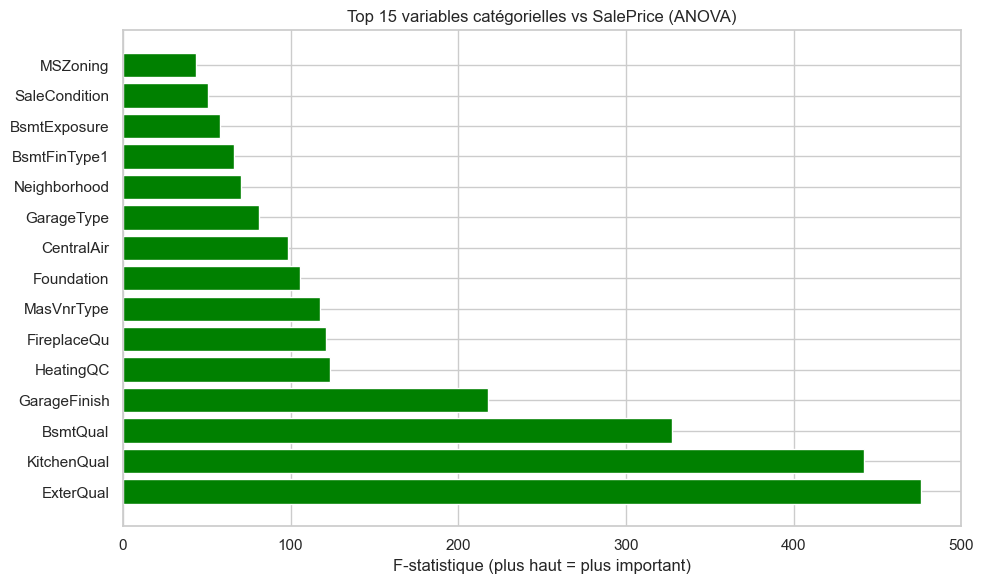

,Variable,F-stat,p-value
17,ExterQual,476.29,0.0
29,KitchenQual,442.00,0.0
20,BsmtQual,327.77,0.0
33,GarageFinish,217.97,0.0
26,HeatingQC,123.38,0.0
31,FireplaceQu,120.96,0.0
16,MasVnrType,117.33,0.0
19,Foundation,105.95,0.0
27,CentralAir,98.44,0.0
32,GarageType,81.04,0.0


In [14]:
from scipy import stats

cat_cols = train.select_dtypes(include="object").columns.tolist()
cat_cols = [c for c in cat_cols if c != TARGET]

anova_results = []
for col in cat_cols:
    groups = [train[train[col] == val][TARGET].values 
              for val in train[col].unique()]
    groups = [g for g in groups if len(g) > 1]
    f_stat, p_val = stats.f_oneway(*groups)
    anova_results.append({
        "Variable": col,
        "F-stat": round(f_stat, 2),
        "p-value": round(p_val, 4)
    })

anova_df = pd.DataFrame(anova_results).sort_values("F-stat", ascending=False)

# Graphique
plt.figure(figsize=(10, 6))
top_cat = anova_df.head(15)
colors = ["green" if p < 0.05 else "red" for p in top_cat["p-value"]]
plt.barh(top_cat["Variable"], top_cat["F-stat"], color=colors)
plt.xlabel("F-statistique (plus haut = plus important)")
plt.title("Top 15 variables catégorielles vs SalePrice (ANOVA)")
plt.tight_layout()
plt.show()

display(anova_df.head(15))

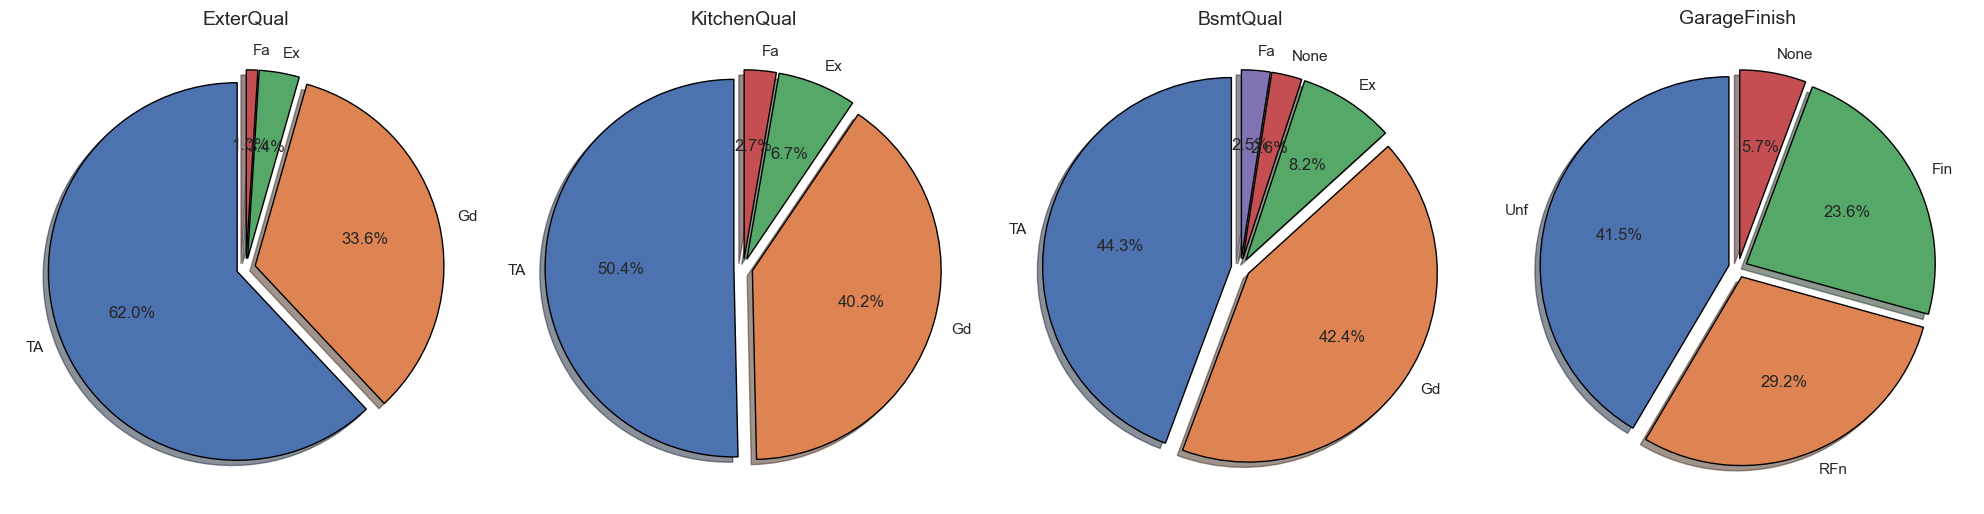

In [15]:
# Top 4 variables catégorielles
top4_cat = ["ExterQual", "KitchenQual", "BsmtQual", "GarageFinish"]

# Création de la figure
fig, axs = plt.subplots(1, 4, figsize=(20, 6))

# Explosion des secteurs
explode = (0.05, 0.05, 0.05, 0.05, 0.05)

# Boucle sur chaque variable
for i, col in enumerate(top4_cat):

    # Comptage des catégories
    counts = train[col].value_counts()

    # Labels
    labels = counts.index.astype(str)

    # Valeurs
    values = counts.values

    # Adapter explode au nombre de catégories
    exp = explode[:len(values)]

    # Pie chart
    axs[i].pie(
        values,
        labels=labels,
        autopct='%1.1f%%',
        startangle=90,
        shadow=True,
        explode=exp,
        wedgeprops={'edgecolor': 'black'}
    )

    # Titre
    axs[i].set_title(col, fontsize=14)

# Ajustement automatique
plt.tight_layout()

# Affichage
plt.show()

In [ ]:
# Encodage ordinal 
# Variables ordinales : l'ordre compte -> map() au lieu de OneHotEncoder
quality_map    = {"None":0,"Po":1,"Fa":2,"TA":3,"Gd":4,"Ex":5}
finish_map     = {"None":0,"Unf":1,"RFn":2,"Fin":3}
exposure_map   = {"None":0,"No":1,"Mn":2,"Av":3,"Gd":4}
bsmtfin_map    = {"None":0,"Unf":1,"LwQ":2,"Rec":3,"BLQ":4,"ALQ":5,"GLQ":6}
functional_map = {"Sal":0,"Sev":1,"Maj2":2,"Maj1":3,"Mod":4,"Min2":5,"Min1":6,"Typ":7}
paved_map      = {"N":0,"P":1,"Y":2}

for df in [train, test]:
    for col in ["ExterQual","ExterCond","HeatingQC","KitchenQual",
                "FireplaceQu","PoolQC","GarageQual","GarageCond",
                "BsmtQual","BsmtCond"]:
        df[col] = df[col].map(quality_map)
    df["GarageFinish"] = df["GarageFinish"].map(finish_map)
    df["BsmtExposure"] = df["BsmtExposure"].map(exposure_map)
    df["BsmtFinType1"] = df["BsmtFinType1"].map(bsmtfin_map)
    df["BsmtFinType2"] = df["BsmtFinType2"].map(bsmtfin_map)
    df["Functional"]   = df["Functional"].map(functional_map)
    df["PavedDrive"]   = df["PavedDrive"].map(paved_map)

print("Encodage ordinal ✓")


Encodage ordinal ✓


## Visualisations des variables numériques
Maintenant que les données sont propres : corrélations avec `log1p(SalePrice)`, heatmap et scatter plots des variables les plus prédictives.


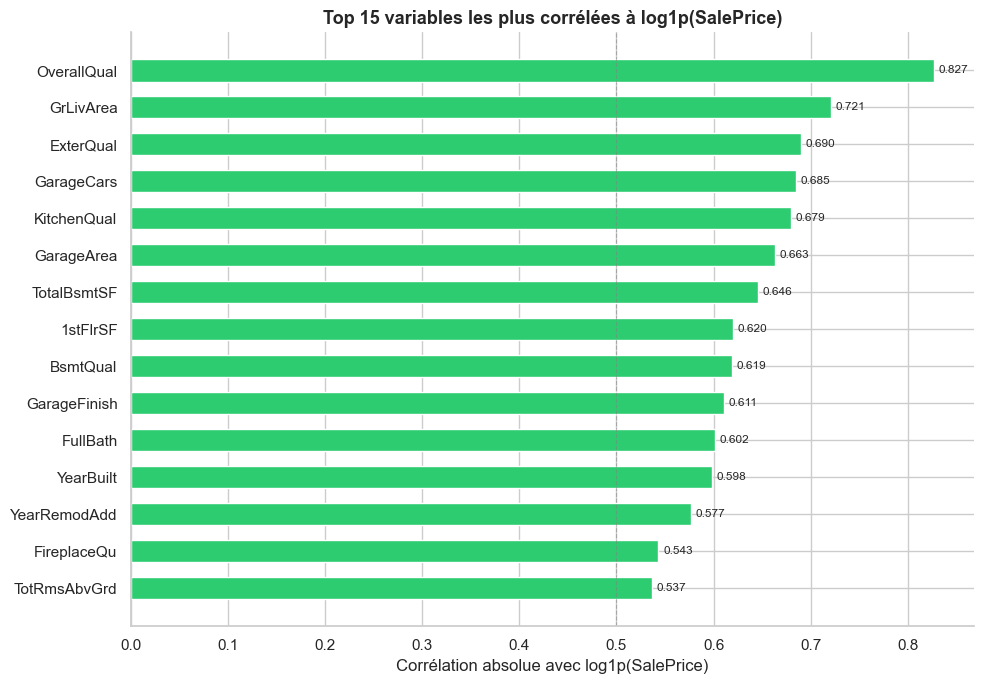

In [17]:
#  Corrélations avec log1p(SalePrice) 
num_cols = [c for c in train.select_dtypes(include=np.number).columns if c != TARGET]

log_target = np.log1p(train[TARGET])
corr = train[num_cols].corrwith(log_target)
corr_sorted = corr.abs().sort_values(ascending=False).head(15)

colors = ["#2ecc71" if corr[c] > 0 else "#e74c3c" for c in corr_sorted.index]

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(corr_sorted.index[::-1], corr_sorted.values[::-1],
               color=colors[::-1], edgecolor="white", height=0.6)
for bar, val in zip(bars, corr_sorted.values[::-1]):
    ax.text(val + 0.005, bar.get_y() + bar.get_height()/2,
            f"{val:.3f}", va="center", fontsize=8.5)
ax.set_xlabel("Corrélation absolue avec log1p(SalePrice)")
ax.set_title("Top 15 variables les plus corrélées à log1p(SalePrice)",
             fontsize=13, fontweight="bold")
ax.axvline(0.5, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout()
plt.show()


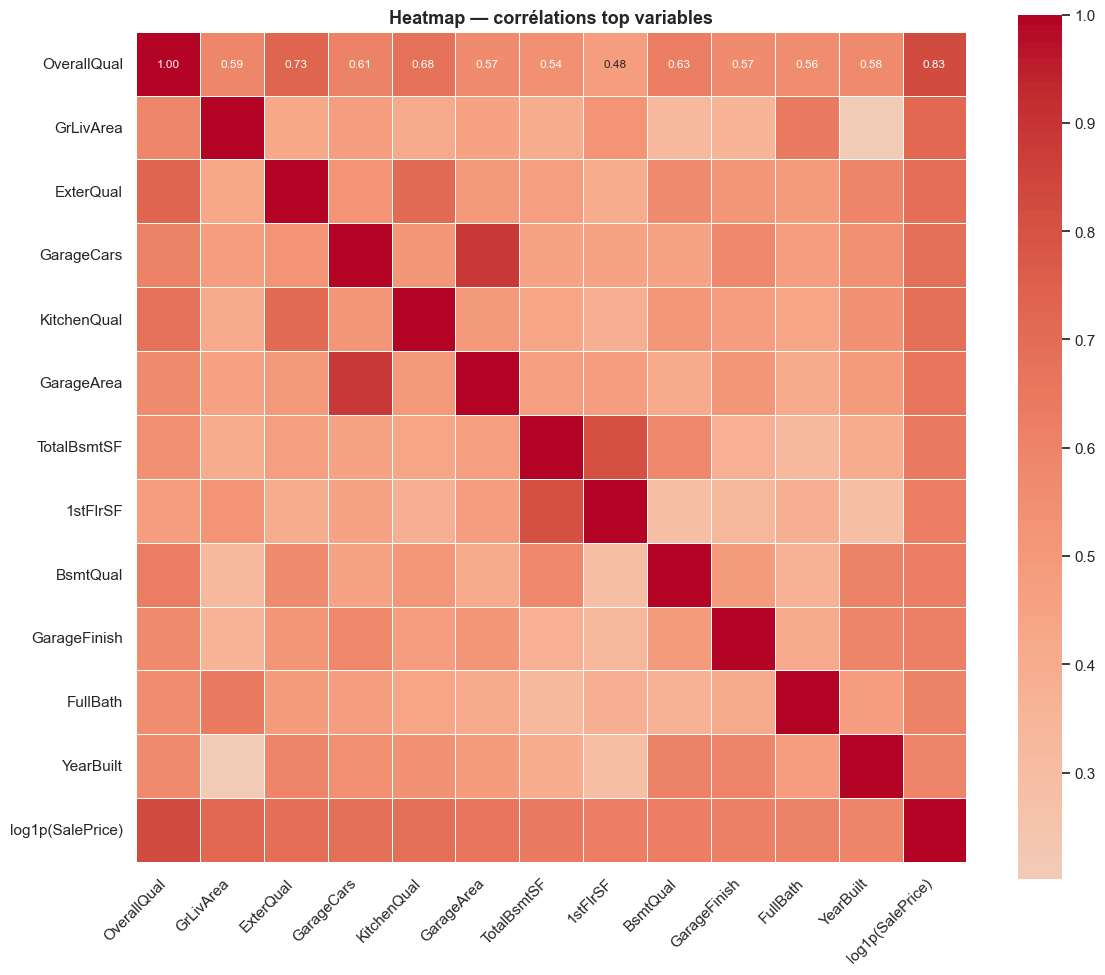

In [19]:
# Heatmap (corrélation entre les variables numériques)
top_vars = corr_sorted.head(12).index.tolist()
df_corr = train[top_vars].copy()
df_corr["log1p(SalePrice)"] = np.log1p(train[TARGET])

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(df_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, square=True, annot_kws={"size": 8.5},
            linewidths=0.5, linecolor="white", ax=ax)
ax.set_title("Heatmap — corrélations top variables", fontsize=13, fontweight="bold")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.show()


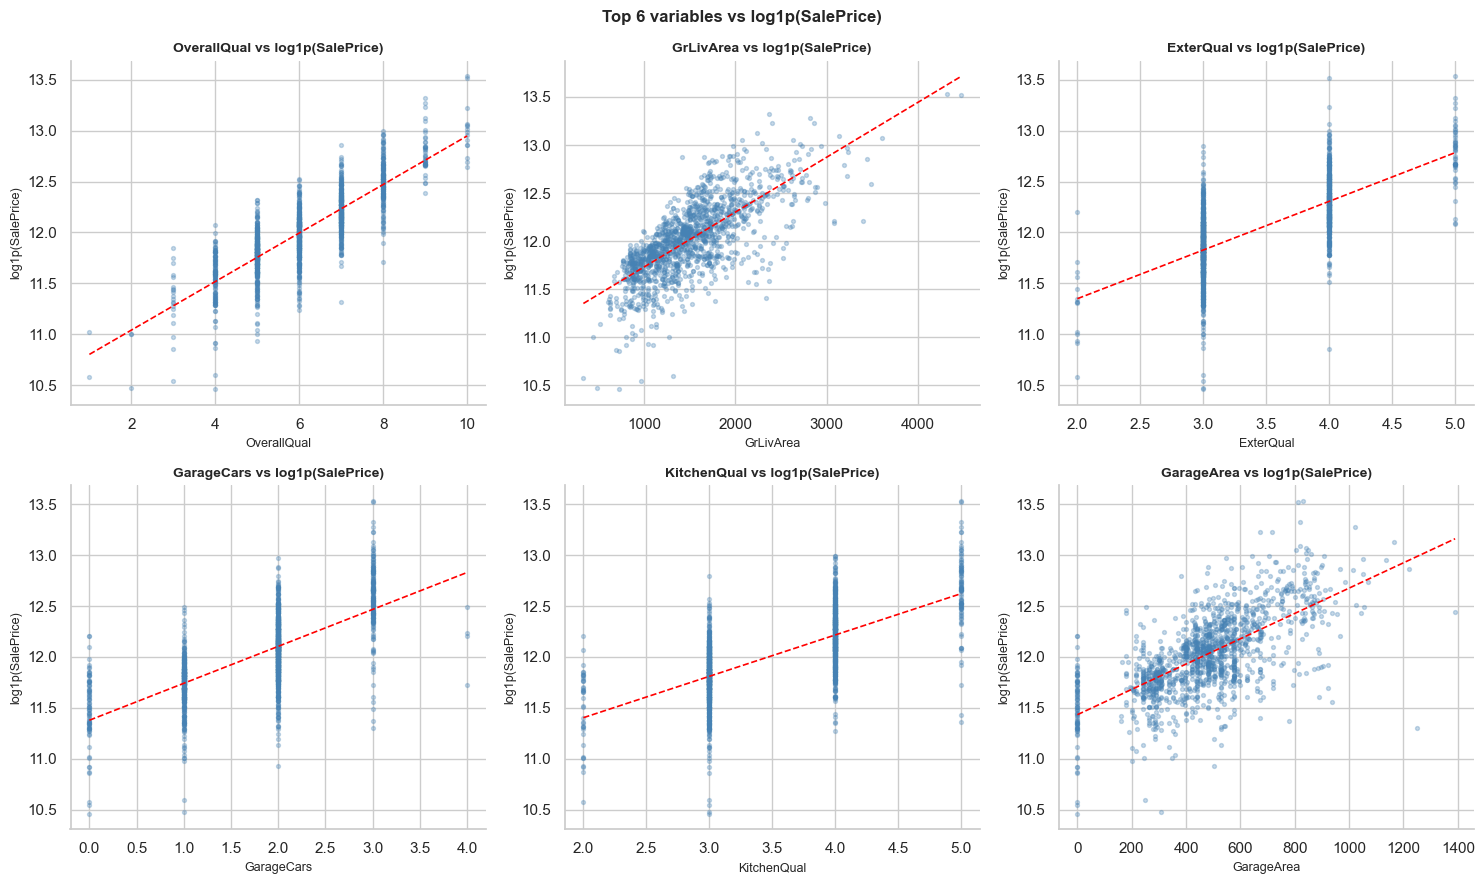

In [20]:
# Scatter plots top 6 vs log1p(SalePrice) 
key_vars = corr_sorted.head(6).index.tolist()
log_target = np.log1p(train[TARGET])

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()
for i, col in enumerate(key_vars):
    axes[i].scatter(train[col], log_target, alpha=0.3, s=8, color="steelblue")
    z = np.polyfit(train[col], log_target, 1)
    x_line = np.linspace(train[col].min(), train[col].max(), 100)
    axes[i].plot(x_line, np.poly1d(z)(x_line), color="red", linewidth=1.2, linestyle="--")
    axes[i].set_xlabel(col, fontsize=9)
    axes[i].set_ylabel("log1p(SalePrice)", fontsize=9)
    axes[i].set_title(f"{col} vs log1p(SalePrice)", fontsize=10, fontweight="bold")
    axes[i].spines[["top","right"]].set_visible(False)
plt.suptitle("Top 6 variables vs log1p(SalePrice)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


## Étape 5— Feature Engineering

Création de nouvelles variables à partir des variables existantes : surfaces totales, indicateurs binaires, âge du bien, interactions qualité × surface. Puis transformation `log1p` des variables asymétriques.


In [21]:
def create_features(df):
    df = df.copy()

    # Surfaces totales
    df["TotalSF"]      = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
    df["TotalPorch"]   = (df["WoodDeckSF"] + df["OpenPorchSF"] +
                          df["EnclosedPorch"] + df["3SsnPorch"] + df["ScreenPorch"])
    df["TotalBath"]    = (df["FullBath"] + 0.5*df["HalfBath"] +
                          df["BsmtFullBath"] + 0.5*df["BsmtHalfBath"])

    # Âge — clip(lower=0) pour éviter log1p(négatif) plus tard
    df["HouseAge"]     = (df["YrSold"] - df["YearBuilt"]).clip(lower=0)
    df["RemodAge"]     = (df["YrSold"] - df["YearRemodAdd"]).clip(lower=0)
    df["WasRemodeled"] = (df["YearBuilt"] != df["YearRemodAdd"]).astype(int)
    df["IsNew"]        = (df["YrSold"] == df["YearBuilt"]).astype(int)

    # Indicateurs binaires
    df["HasPool"]      = (df["PoolArea"] > 0).astype(int)
    df["HasGarage"]    = (df["GarageArea"] > 0).astype(int)
    df["HasFireplace"] = (df["Fireplaces"] > 0).astype(int)
    df["Has2ndFloor"]  = (df["2ndFlrSF"] > 0).astype(int)

    # Interaction qualité × surface
    df["QualxSF"] = df["OverallQual"] * df["GrLivArea"]

    return df

train = create_features(train)
test  = create_features(test)

print("Feature Engineering ✓")
print(f"Train shape : {train.shape}")


Feature Engineering ✓
Train shape : (1426, 91)


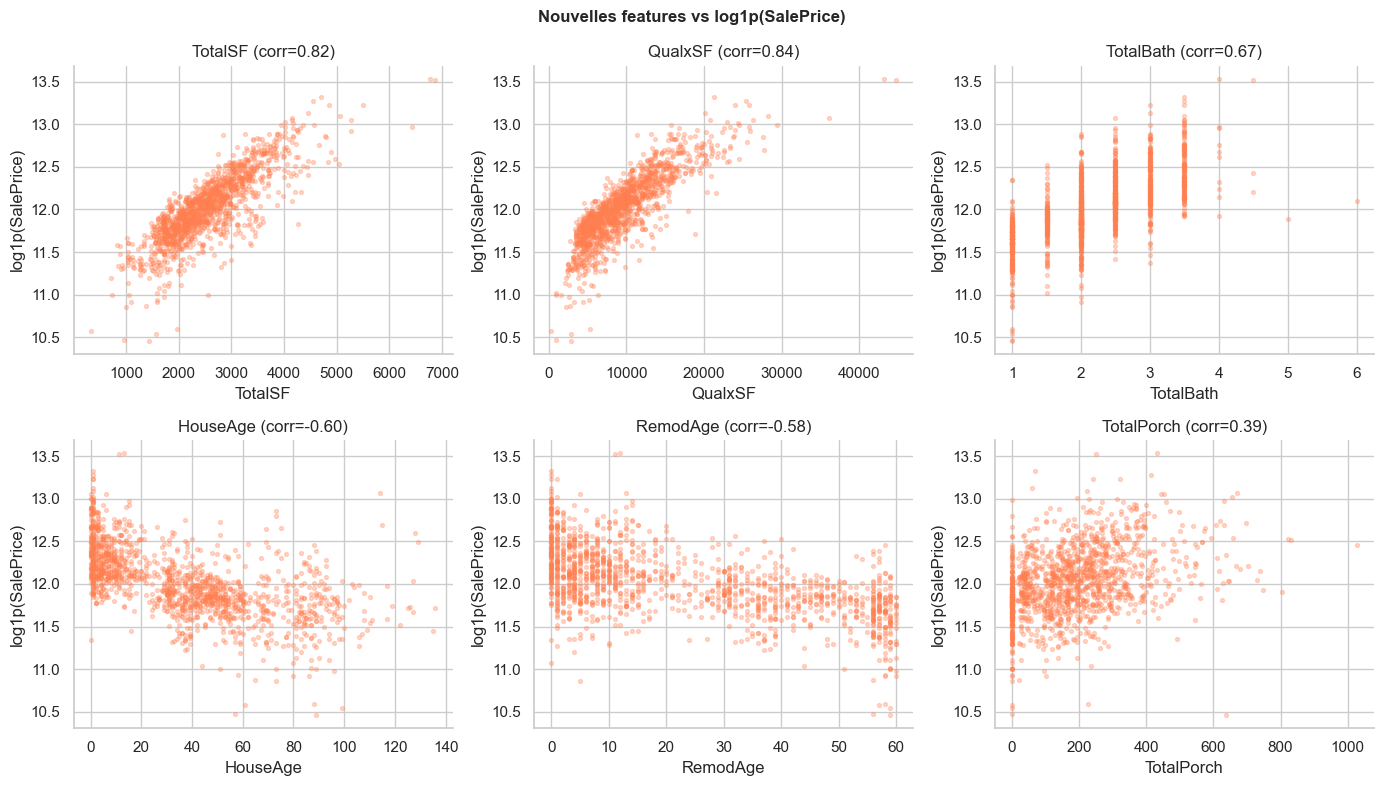

In [22]:
# Visualisation des nouvelles features
log_target = np.log1p(train[TARGET])
top_new = ["TotalSF","QualxSF","TotalBath","HouseAge","RemodAge","TotalPorch"]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()
for i, col in enumerate(top_new):
    axes[i].scatter(train[col], log_target, alpha=0.3, s=8, color="coral")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("log1p(SalePrice)")
    axes[i].set_title(f"{col} (corr={train[col].corr(log_target):.2f})")
    axes[i].spines[["top","right"]].set_visible(False)
plt.suptitle("Nouvelles features vs log1p(SalePrice)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


In [23]:
# Transformation log1p sur variables asymétriques 
num_cols    = [c for c in train.select_dtypes(include=np.number).columns if c != TARGET]
skew_series = train[num_cols].skew().sort_values(ascending=False)
cols_to_log = skew_series[skew_series.abs() > 0.75].index.tolist()

for col in cols_to_log:
    train[col] = np.log1p(train[col].clip(lower=0))
    test[col]  = np.log1p(test[col].clip(lower=0))

print(f"Transformation log1p : {len(cols_to_log)} variables ✓")


Transformation log1p : 35 variables ✓


## Étape 6 — Pipeline de Prétraitement

Construction du pipeline `scikit-learn` : imputation des valeurs manquantes, `RobustScaler` pour les numériques, `OneHotEncoder` pour les catégorielles. Transformation appliquée une seule fois sur l'ensemble du train.


In [24]:
all_features = [c for c in train.columns if c != TARGET]
num_features = list(train[all_features].select_dtypes(include=np.number).columns)
cat_features = list(train[all_features].select_dtypes(include="object").columns)

print(f"Features numériques   : {len(num_features)}")
print(f"Features catégorielles: {len(cat_features)}")

X            = train[all_features].copy()
y            = np.log1p(train[TARGET])
X_test_final = test[all_features].copy()

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  RobustScaler())
])
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_features),
    ("cat", cat_pipeline, cat_features)
])

# Prétraitement UNE seule fois sur tout X
preprocessor.fit(X)
X_prep      = preprocessor.transform(X)
X_test_prep = preprocessor.transform(X_test_final)

print(f"X_prep      : {X_prep.shape}")
print(f"X_test_prep : {X_test_prep.shape}")
print("Pipeline ✓")


Features numériques   : 64
Features catégorielles: 26
X_prep      : (1426, 243)
X_test_prep : (1459, 243)
Pipeline ✓


## Étape 7 — Benchmark des Modèles (Cross-Validation)

Évaluation par cross-validation 7-fold sur 100 % du train. Modèles testés : Ridge, Lasso, ElasticNet, GradientBoosting, XGBoost, LightGBM, CatBoost.


In [25]:
def rmsle_cv(model, X, y, n_folds=7):
    """RMSLE par cross-validation — métrique officielle Kaggle"""
    kf = KFold(n_splits=n_folds, shuffle=True, random_state=SEED)
    # X est déjà transformé → pas de pipeline ici
    scores = -cross_val_score(model, X, y,
                               scoring="neg_root_mean_squared_error",
                               cv=kf, n_jobs=-1)
    return scores

models = {
    "Ridge":            Ridge(alpha=10, random_state=SEED),
    "Lasso":            Lasso(alpha=0.0005, max_iter=10000, random_state=SEED),
    "ElasticNet":       ElasticNet(alpha=0.0005, l1_ratio=0.5,
                                   max_iter=10000, random_state=SEED),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=300,
                            learning_rate=0.05, max_depth=4, random_state=SEED),
    "XGBoost":          XGBRegressor(n_estimators=500, learning_rate=0.05,
                            max_depth=4, subsample=0.8, colsample_bytree=0.8,
                            random_state=SEED, verbosity=0),
    "LightGBM":         LGBMRegressor(n_estimators=500, learning_rate=0.05,
                            num_leaves=31, random_state=SEED, verbose=-1),
}

try:
    models["CatBoost"] = CatBoostRegressor(iterations=500, learning_rate=0.05,
                            depth=6, random_state=SEED, verbose=0)
except:
    print("CatBoost non disponible")

print("Modèles à tester :", list(models.keys()))


Modèles à tester : ['Ridge', 'Lasso', 'ElasticNet', 'GradientBoosting', 'XGBoost', 'LightGBM', 'CatBoost']


✓ Ridge                → 0.11125 ± 0.00959
✓ Lasso                → 0.10941 ± 0.00842
✓ ElasticNet           → 0.10984 ± 0.00868
✓ GradientBoosting     → 0.11522 ± 0.00992
✓ XGBoost              → 0.11254 ± 0.01068
✓ LightGBM             → 0.12169 ± 0.01104
✓ CatBoost             → 0.11229 ± 0.01089

RÉSULTATS (trié par CV Moyen — plus bas = mieux)


,Modèle,CV Moyen,CV Std,CV Min,CV Max
1,Lasso,0.10941,0.00842,0.09546,0.11916
2,ElasticNet,0.10984,0.00868,0.09543,0.11908
0,Ridge,0.11125,0.00959,0.09658,0.12183
6,CatBoost,0.11229,0.01089,0.09875,0.12258
4,XGBoost,0.11254,0.01068,0.09631,0.12301
3,GradientBoosting,0.11522,0.00992,0.09957,0.12529
5,LightGBM,0.12169,0.01104,0.10165,0.13518


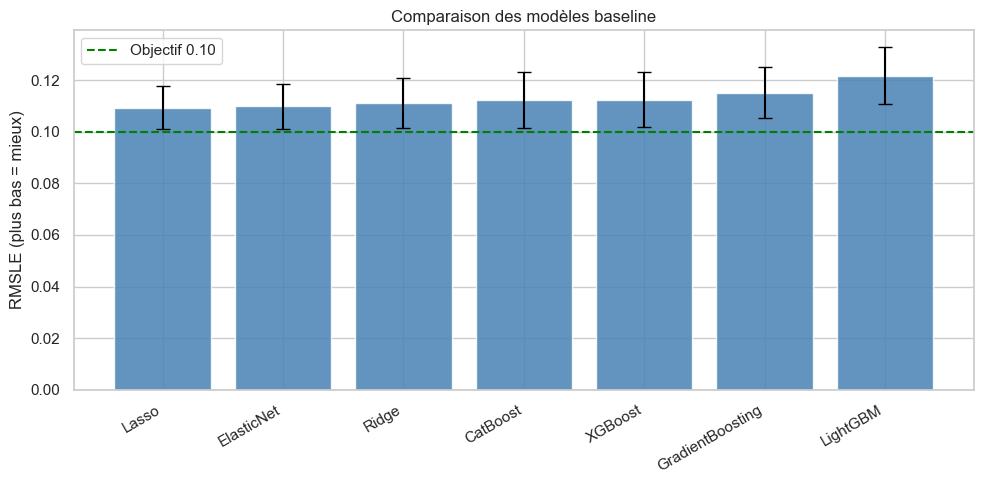

In [26]:
results = []

for name, model in models.items():
    scores = rmsle_cv(model, X_prep, y)
    results.append({
        "Modèle":   name,
        "CV Moyen": round(scores.mean(), 5),
        "CV Std":   round(scores.std(),  5),
        "CV Min":   round(scores.min(),  5),
        "CV Max":   round(scores.max(),  5),
    })
    print(f"✓ {name:20s} → {scores.mean():.5f} ± {scores.std():.5f}")

results_df = pd.DataFrame(results).sort_values("CV Moyen")
print("\n" + "="*55)
print("RÉSULTATS (trié par CV Moyen — plus bas = mieux)")
print("="*55)
display(results_df)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(results_df))
ax.bar(x, results_df["CV Moyen"], color="steelblue", alpha=0.85)
ax.errorbar(x, results_df["CV Moyen"], yerr=results_df["CV Std"],
            fmt="none", color="black", capsize=5)
ax.axhline(0.10, color="green", linestyle="--", label="Objectif 0.10")
ax.set_xticks(x)
ax.set_xticklabels(results_df["Modèle"], rotation=30, ha="right")
ax.set_ylabel("RMSLE (plus bas = mieux)")
ax.set_title("Comparaison des modèles baseline")
ax.legend()
plt.tight_layout()
plt.show()


## Étape 8 — Optimisation des Hyperparamètres (GridSearchCV)

Recherche des meilleurs hyperparamètres pour Ridge, Lasso et ElasticNet via `GridSearchCV` avec validation croisée 5-fold.


In [27]:
# GridSearch sur X pour trouver les meilleurs params

# --- Lasso ---
lasso_gs = GridSearchCV(
    Pipeline([("prep", preprocessor),
              ("model", Lasso(max_iter=10000, random_state=SEED))]),
    {"model__alpha": [0.0001, 0.0003, 0.0005, 0.001, 0.005, 0.01]},
    cv=7, scoring="neg_root_mean_squared_error", n_jobs=-1
)
lasso_gs.fit(X, y)
print(f"Lasso  → alpha={lasso_gs.best_params_['model__alpha']}  RMSLE={-lasso_gs.best_score_:.5f}")

# --- Ridge ---
ridge_gs = GridSearchCV(
    Pipeline([("prep", preprocessor),
              ("model", Ridge(random_state=SEED))]),
    {"model__alpha": [0.5, 1, 5, 10, 20, 50, 100, 200]},
    cv=7, scoring="neg_root_mean_squared_error", n_jobs=-1
)
ridge_gs.fit(X, y)
print(f"Ridge  → alpha={ridge_gs.best_params_['model__alpha']}  RMSLE={-ridge_gs.best_score_:.5f}")

# --- ElasticNet ---
enet_gs = GridSearchCV(
    Pipeline([("prep", preprocessor),
              ("model", ElasticNet(max_iter=10000, random_state=SEED))]),
    {"model__alpha":   [0.0001, 0.0005, 0.001, 0.005],
     "model__l1_ratio": [0.1, 0.5, 0.9]},
    cv=7, scoring="neg_root_mean_squared_error", n_jobs=-1
)
enet_gs.fit(X, y)
print(f"ElasticNet → {enet_gs.best_params_}  RMSLE={-enet_gs.best_score_:.5f}")


Lasso  → alpha=0.0003  RMSLE=0.10845
Ridge  → alpha=5  RMSLE=0.11051
ElasticNet → {'model__alpha': 0.0005, 'model__l1_ratio': 0.9}  RMSLE=0.10839


## Étape 9 — Stacking (Combinaison de Modèles)

Assemblage de modèles par **stacking** : les prédictions des modèles de base (Ridge, Lasso, ElasticNet, GradientBoosting, LightGBM, CatBoost) deviennent les features d'un méta-modèle Ridge.


In [28]:
base_learners = [
    ("ridge", Ridge(alpha=ridge_gs.best_params_["model__alpha"], random_state=SEED)),
    ("lasso", Lasso(alpha=lasso_gs.best_params_["model__alpha"],
                   max_iter=10000, random_state=SEED)),
    ("enet",  ElasticNet(alpha=enet_gs.best_params_["model__alpha"],
                         l1_ratio=enet_gs.best_params_["model__l1_ratio"],
                         max_iter=10000, random_state=SEED)),
    ("gb",    GradientBoostingRegressor(n_estimators=300, learning_rate=0.05,
                                         max_depth=4, random_state=SEED)),
    
    ("lgbm",  LGBMRegressor(n_estimators=500, learning_rate=0.05,
                             num_leaves=31, random_state=SEED, verbose=-1)),
]

try:
    base_learners.append(
        ("catboost", CatBoostRegressor(iterations=500, learning_rate=0.05,
                                        depth=6, random_state=SEED, verbose=0))
    )
    print("✓ CatBoost ajouté")
except:
    print("CatBoost ignoré")

stacking_model = StackingRegressor(
    estimators=base_learners,
    final_estimator=Ridge(alpha=1.0),
    cv=7,
    n_jobs=-1
)

print(f"Modèles de base : {[name for name, _ in base_learners]}")
print("Stacking défini ✓")


✓ CatBoost ajouté
Modèles de base : ['ridge', 'lasso', 'enet', 'gb', 'lgbm', 'catboost']
Stacking défini ✓


In [29]:
# Évaluation par CV — X_prep déjà transformé, pas de pipeline
print("Évaluation du stacking (2-3 minutes)...")

stack_scores = cross_val_score(
    stacking_model, X_prep, y,
    cv=KFold(n_splits=5, shuffle=True, random_state=SEED),
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
stack_rmsle = -stack_scores

print("\n" + "="*45)
print(f"Stacking RMSLE : {stack_rmsle.mean():.5f} ± {stack_rmsle.std():.5f}")
print("="*45)


Évaluation du stacking (2-3 minutes)...

Stacking RMSLE : 0.10634 ± 0.00307


COMPARAISON FINALE


,Modèle,RMSLE
3,⭐ STACKING,0.10634
2,ElasticNet (optimisé),0.10839
1,Lasso (optimisé),0.10845
0,Ridge (optimisé),0.11051


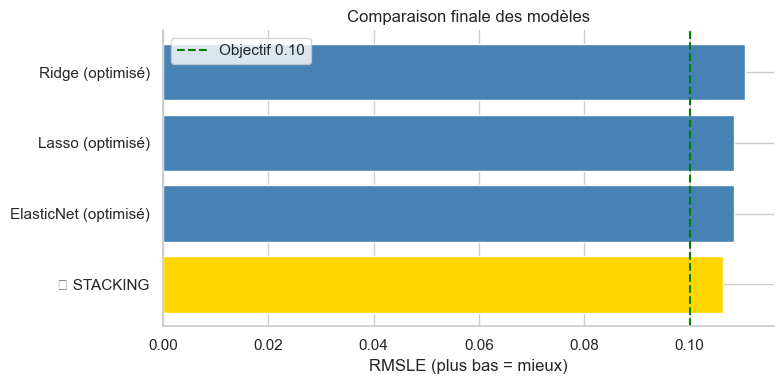

In [30]:
# Comparaison finale
final_comparison = pd.DataFrame([
    {"Modèle": "Ridge (optimisé)",      "RMSLE": round(-ridge_gs.best_score_, 5)},
    {"Modèle": "Lasso (optimisé)",      "RMSLE": round(-lasso_gs.best_score_, 5)},
    {"Modèle": "ElasticNet (optimisé)", "RMSLE": round(-enet_gs.best_score_,  5)},
    {"Modèle": "⭐ STACKING",           "RMSLE": round(stack_rmsle.mean(),     5)},
]).sort_values("RMSLE")

print("COMPARAISON FINALE")
display(final_comparison)

fig, ax = plt.subplots(figsize=(8, 4))
colors = ["gold" if "STACKING" in m else "steelblue" for m in final_comparison["Modèle"]]
ax.barh(final_comparison["Modèle"], final_comparison["RMSLE"], color=colors)
ax.axvline(0.10, color="green", linestyle="--", label="Objectif 0.10")
ax.set_xlabel("RMSLE (plus bas = mieux)")
ax.set_title("Comparaison finale des modèles")
ax.legend()
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout()
plt.show()


## Étape 10 — Soumission Kaggle

Réentraînement du modèle final sur 100 % des données d'entraînement, prédiction sur le jeu de test, puis export du fichier `submission_R4.csv` au format attendu par Kaggle.


In [31]:
# Réentraîner sur TOUTES les données (100% du train)
print("Réentraînement sur toutes les données...")
stacking_model.fit(X_prep, y)
print("Entraînement terminé ✓")

# Prédictions sur le vrai test Kaggle
log_predictions   = stacking_model.predict(X_test_prep)
final_predictions = np.expm1(log_predictions)

print(f"\nPrix min prédit   : {final_predictions.min():>10,.0f} $")
print(f"Prix max prédit   : {final_predictions.max():>10,.0f} $")
print(f"Prix médian prédit: {np.median(final_predictions):>10,.0f} $")

submission = pd.DataFrame({
    "Id":        test_ids.values,
    "SalePrice": final_predictions
})
submission.to_csv("submission_R4.csv", index=False)
print("\nsubmission_R4.csv sauvegardé ✓")
display(submission.head())


Réentraînement sur toutes les données...
Entraînement terminé ✓

Prix min prédit   :     40,944 $
Prix max prédit   :    827,976 $
Prix médian prédit:    156,726 $

submission_R4.csv sauvegardé ✓


,Id,SalePrice
0,1461,121018.422771
1,1462,157499.220826
2,1463,180523.506659
3,1464,196851.436582
4,1465,195033.631189
